In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf
from matplotlib import colors

# plotting function
def plot_map(dataarray, title='', cmap='viridis', cmap_split = '', discrete_cmap=0, vmin=None, vmax=None, borders=False, norm=None, cbar_label= '', cbar_loc = 'bottom', svg=False, grid_labels=False, local_map=False):
    
    if cmap_split=='low':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.0, 0.5)
    elif cmap_split=='high':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.5, 1.0)
    elif cmap_split=='trim':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.1, 0.9)
    else:
        custom_cmap = plt.get_cmap(cmap)

    if discrete_cmap != 0:
        custom_cmap = discrete_colormap(custom_cmap, discrete_cmap)

    if cbar_label=='':
        cbar_label = dataarray.name
        
    plt.figure(figsize=(12, 8))
    if local_map == False:
        ax = plt.axes(projection=ccrs.Robinson())
    else: # for local maps use PlateCarree projection
        ax = plt.axes(projection=ccrs.PlateCarree())
    # plot only nans in grey. supress cbar
    xr.where(dataarray.isnull(), 1, np.nan).plot(ax=ax, cmap=colors.ListedColormap(['lightgrey']), vmin=1, vmax=1, transform=ccrs.PlateCarree(), add_colorbar=False)
    # plot data
    dataarray.plot(ax=ax, cmap=custom_cmap, vmin=vmin, vmax=vmax, norm=norm, cbar_kwargs={'label': cbar_label, 'location': cbar_loc, 'fraction': 0.06, 'pad': 0.05, 'ticks': np.linspace(vmin + (vmin/discrete_cmap), vmax + (vmax/discrete_cmap), int((discrete_cmap + 1)/2)+1) if discrete_cmap else None}, transform=ccrs.PlateCarree())    
    ax.coastlines() # coastlines for context

    ax.add_feature(cf.OCEAN, facecolor='white', zorder=5)
    if borders: # country borders toggle
        ax.add_feature(cf.BORDERS)

    if grid_labels:
        # show only major longitude/latitude labels using gridlines
        lon_ticks = [-180, -120, -60, 0, 60, 120, 180]
        lat_ticks = [-45, -30, -15, 0, 15, 30, 45]

        gl = ax.gridlines(
            crs=ccrs.PlateCarree(),
            draw_labels=True,
            linewidth=0,
            x_inline=False,
            y_inline=False,
        )
        # show only bottom and left labels
        gl.top_labels = False
        gl.right_labels = False
        gl.bottom_labels = True
        gl.left_labels = True
        gl.xlocator = FixedLocator(lon_ticks)
        gl.ylocator = FixedLocator(lat_ticks)
        gl.xformatter = LongitudeFormatter()
        gl.yformatter = LatitudeFormatter()
        gl.xlabel_style = {'size': 10}
        gl.ylabel_style = {'size': 10}

    ax.set_title(title)
    if svg:
        plt.savefig("../export/map_{}.svg".format(dataarray.name), format='svg', bbox_inches='tight')
    plt.show()

# convert a continous cmap to a graduated discrete cmap with n discrete colors. eg, 5 discrete colors from a continuous cmap
def discrete_colormap(cmap, n):
    cmap = plt.get_cmap(cmap)
    new_cmap = colors.ListedColormap(
        cmap(np.linspace(0, 1, n)))
    return new_cmap

In [2]:
lpjml1 = xr.open_dataset('../data-raw/ISIMIP/rootmoist/obsclim_histsoc/lpjml5-7-10-fire_gswp3-w5e5_obsclim_histsoc_default_rootmoist_global_monthly_1901_2019.nc')
# depth integration to get the total root moisture content in the soil column in mm
# rootmoist is in kg/m2 (= mm), so simply add the values for each layer to get the total root moisture content in the soil column in mm
rm = lpjml1.rootmoist.sum(dim='depth')
rm = rm.sel(lat=slice(75, -60))

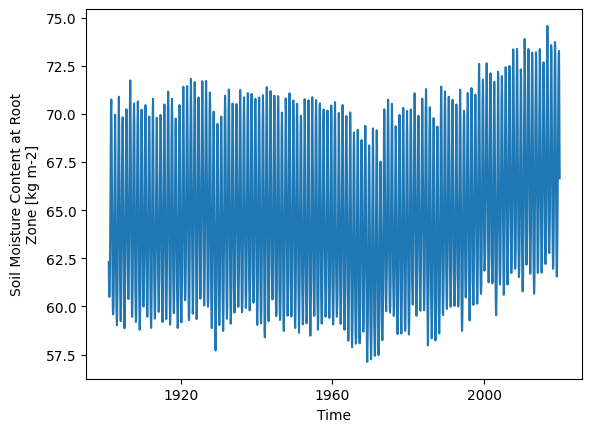

In [11]:
rm.mean(dim='lat').mean(dim='lon').plot()

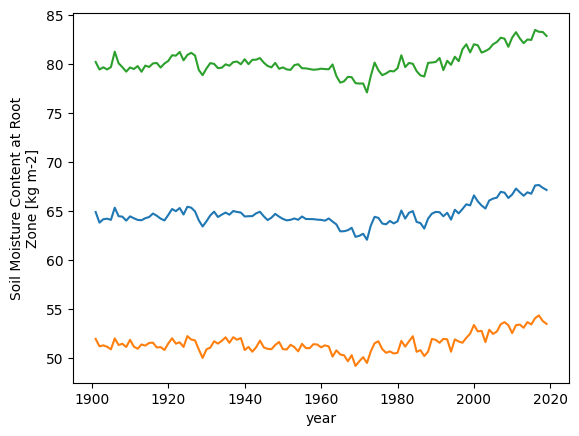

In [4]:
# plot annualglobal mean as a line plot with annual min max as shaded area
rm_annual = rm.groupby('time.year').mean(dim='time').mean(dim=['lat', 'lon'])
rm_annual_min = rm.groupby('time.year').min(dim='time').mean(dim=['lat', 'lon'])
rm_annual_max = rm.groupby('time.year').max(dim='time').mean(dim=['lat', 'lon'])

rm_annual.plot()
rm_annual_min.plot()
rm_annual_max.plot()

In [3]:
# period max global maps
rm_1901_1930_mean = rm.sel(time=slice('1901-01-01', '1930-12-31')).mean(dim='time')
rm_1931_1960_mean = rm.sel(time=slice('1931-01-01', '1960-12-31')).mean(dim='time')
rm_1961_1990_mean = rm.sel(time=slice('1961-01-01', '1990-12-31')).mean(dim='time')
rm_1991_2020_mean = rm.sel(time=slice('1991-01-01', '2019-12-31')).mean(dim='time')

rm_1901_1930_p95 = rm.sel(time=slice('1901-01-01', '1930-12-31')).quantile(0.95, dim='time')
rm_1931_1960_p95 = rm.sel(time=slice('1931-01-01', '1960-12-31')).quantile(0.95, dim='time')
rm_1961_1990_p95 = rm.sel(time=slice('1961-01-01', '1990-12-31')).quantile(0.95, dim='time')
rm_1991_2020_p95 = rm.sel(time=slice('1991-01-01', '2019-12-31')).quantile(0.95, dim='time')

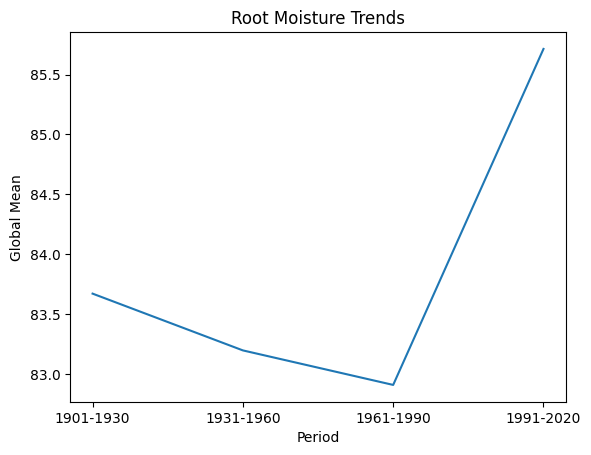

In [10]:
# plot global mean for each period
rm_1901_1930_global_p95 = rm_1901_1930_p95.mean(dim=['lat', 'lon'])
rm_1931_1960_global_p95 = rm_1931_1960_p95.mean(dim=['lat', 'lon'])
rm_1961_1990_global_p95 = rm_1961_1990_p95.mean(dim=['lat', 'lon'])
rm_1991_2020_global_p95 = rm_1991_2020_p95.mean(dim=['lat', 'lon'])

# line plot of global mean for each period
import matplotlib.pyplot as plt
plt.plot(['1901-1930', '1931-1960', '1961-1990', '1991-2020'], [rm_1901_1930_global_p95, rm_1931_1960_global_p95, rm_1961_1990_global_p95, rm_1991_2020_global_p95])
plt.xlabel('Period')
plt.ylabel('Global Mean')
plt.title('Root Moisture Trends')
plt.show()

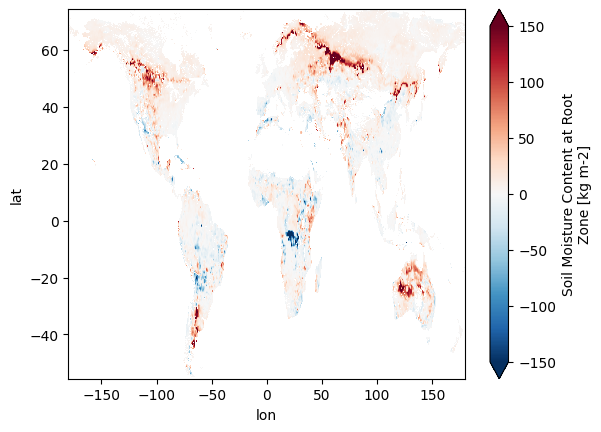

In [73]:
(rm_1991_2020_mean- rm_1961_1990_mean).plot(cmap='RdBu_r', vmin=-150, vmax=150)

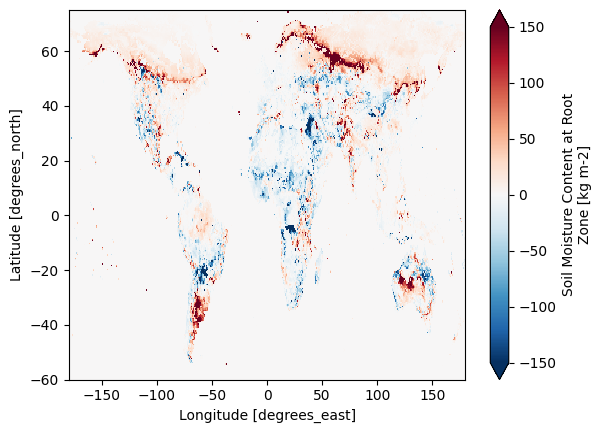

In [34]:
(rm_1991_2020_mean - rm_1901_1930_mean).plot(vmin=-150, vmax=150, cmap='RdBu_r')

In [5]:
# save nan mask
nanMask = xr.open_dataarray("../data/SR-target/nanMask.nc").rename("nanMask")

# interp like nanMask and apply the mask (has value 1 for cells to mask)
rm_1901_1930_mean = rm_1901_1930_mean.interp_like(nanMask)
rm_1901_1930_mean = rm_1901_1930_mean.where(nanMask != 1)

rm_1931_1960_mean = rm_1931_1960_mean.interp_like(nanMask)
rm_1931_1960_mean = rm_1931_1960_mean.where(nanMask != 1)

rm_1961_1990_mean = rm_1961_1990_mean.interp_like(nanMask)
rm_1961_1990_mean = rm_1961_1990_mean.where(nanMask != 1)

rm_1991_2020_mean = rm_1991_2020_mean.interp_like(nanMask)
rm_1991_2020_mean = rm_1991_2020_mean.where(nanMask != 1)

rm_1901_1930_p95 = rm_1901_1930_p95.interp_like(nanMask)
rm_1901_1930_p95 = rm_1901_1930_p95.where(nanMask != 1)

rm_1931_1960_p95 = rm_1931_1960_p95.interp_like(nanMask)
rm_1931_1960_p95 = rm_1931_1960_p95.where(nanMask != 1)

rm_1961_1990_p95 = rm_1961_1990_p95.interp_like(nanMask)
rm_1961_1990_p95 = rm_1961_1990_p95.where(nanMask != 1)

rm_1991_2020_p95 = rm_1991_2020_p95.interp_like(nanMask)
rm_1991_2020_p95 = rm_1991_2020_p95.where(nanMask != 1)

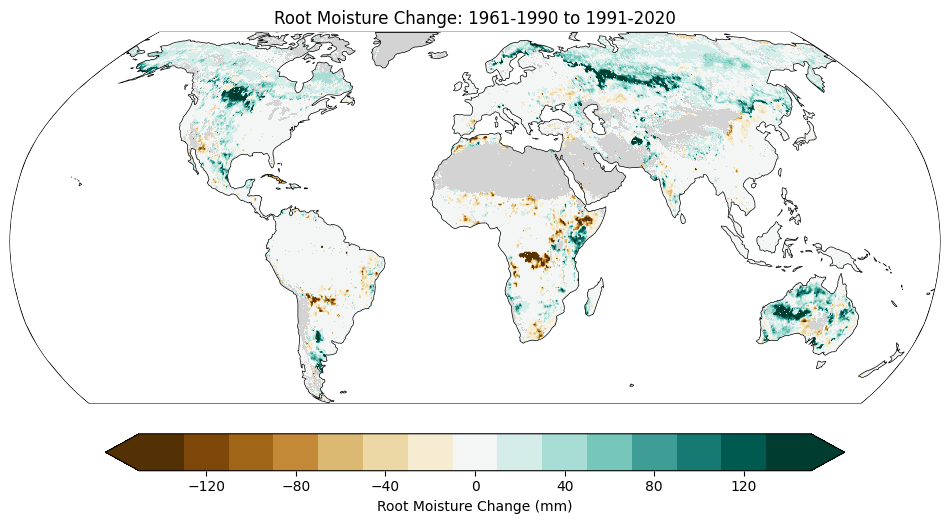

In [29]:
plot_map(rm_1991_2020_p95 - rm_1961_1990_p95, title='Root Moisture Change: 1961-1990 to 1991-2020',
         cmap='BrBG', vmin=-150, vmax=150, discrete_cmap=15,
         cbar_label='Root Moisture Change (mm)')

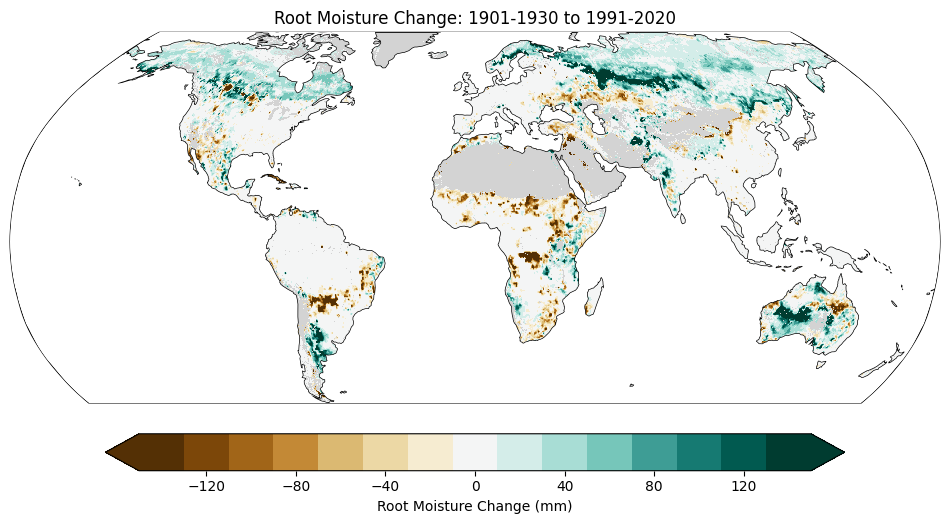

In [30]:
plot_map(rm_1991_2020_p95 - rm_1901_1930_p95, title='Root Moisture Change: 1901-1930 to 1991-2020',
         cmap='BrBG', vmin=-150, vmax=150, discrete_cmap=15,
         cbar_label='Root Moisture Change (mm)')

In [6]:
deltaSR20c = xr.open_dataarray("../export/deltaSR_20thC.nc").rename("deltaSR_ml")
sr_1901_1930 = xr.open_dataarray("../export/sr_1901_1930.nc").rename("sr_1901_1930")

# plot relative change of rootmoist vs deltaSR20c
deltaSR20c_rel = deltaSR20c / sr_1901_1930
delta_rm = rm_1991_2020_p95 - rm_1901_1930_p95
delta_rm_rel = delta_rm / rm_1901_1930_p95

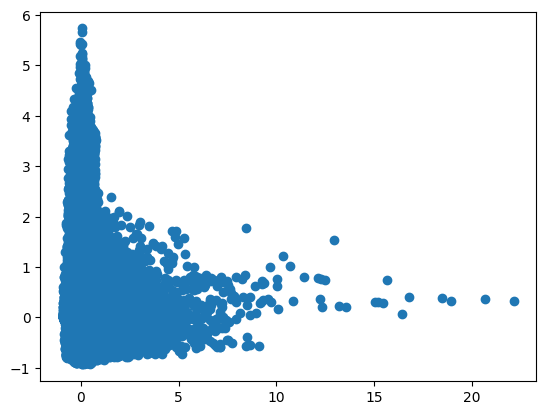

In [22]:
# plot relative change of rootmoist vs deltaSR20c scatter
plt.scatter(deltaSR20c_rel.values.flatten(), delta_rm_rel.values.flatten())

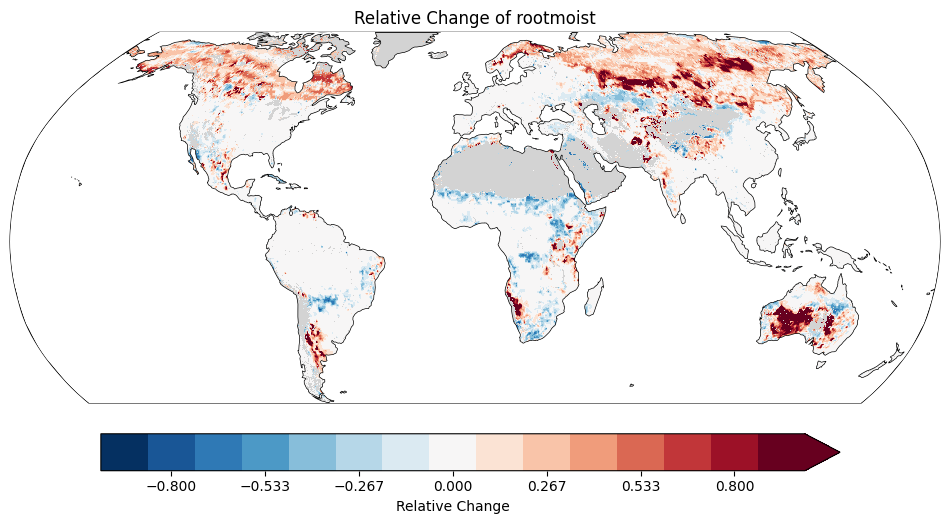

In [24]:
plot_map(delta_rm_rel, title='Relative Change of rootmoist', cmap='RdBu_r', vmin=-1, vmax=1, discrete_cmap=15, cbar_label='Relative Change')

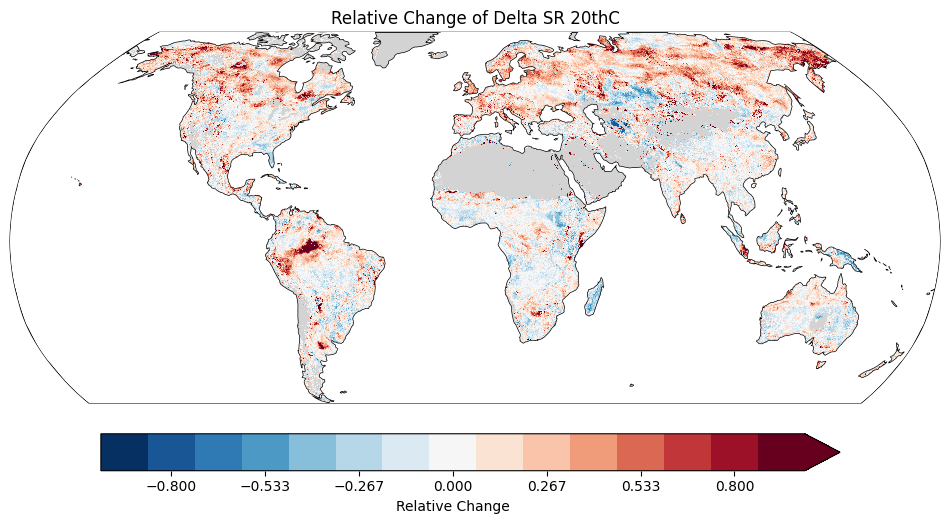

In [23]:
plot_map(deltaSR20c_rel, title='Relative Change of Delta SR 20thC', cmap='RdBu_r', vmin=-1, vmax=1, discrete_cmap=15, cbar_label='Relative Change')

In [8]:
# resample rm to match nanMask and apply the mask (has value 1 for cells to mask)
rmMasked = rm.interp_like(nanMask)
rmMasked = rmMasked.where(nanMask != 1)

In [ ]:
# de-seasonalize and detrend the time series and check stationarity again
# deseasonalize: subtract the monthly mean from each month in the time series for each grid cell
# there are different trends along the entire period
# so we deseasonalize and detrend sperately for different periods, and then check stationarity for each period
# periods: 1901-1927, 1991-2019

monthly_mean_1901_1927 = rm.sel(time=slice('1901', '1927')).groupby('time.month').mean(dim='time')
monthly_mean_1991_2019 = rm.sel(time=slice('1991', '2019')).groupby('time.month').mean(dim='time')

rm_deseasonalized_1901_1927 = rm.sel(time=slice('1901', '1927')).groupby('time.month') - monthly_mean_1901_1927
rm_deseasonalized_1991_2019 = rm.sel(time=slice('1991', '2019')).groupby('time.month') - monthly_mean_1991_2019

# detrend: subtract the linear trend from the time series for each grid cell
from scipy.signal import detrend
def detrend_grid(ts):
    if np.isnan(ts).all(): # if all values are nan, return the ts
        return ts
    # if values are constant, return ts (no change)
    elif np.all(ts == ts[0]):
        return ts
    else:
        return detrend(ts)

# apply the function to each grid cell in the rm_deseasonalized DataArray (time, lat, lon)  along time dimension
rm_deseasonalized_detrended_1901_1927 = xr.apply_ufunc(detrend_grid,
                                                     rm_deseasonalized_1901_1927, input_core_dims=[['time']], output_core_dims=[['time']],
                                                     vectorize=True, dask='parallelized', output_dtypes=[float])
rm_deseasonalized_detrended_1991_2019 = xr.apply_ufunc(detrend_grid,
                                                     rm_deseasonalized_1991_2019, input_core_dims=[['time']], output_core_dims=[['time']],
                                                     vectorize=True, dask='parallelized', output_dtypes=[float])
#rm_deseasonalized_detrended_1901_1927.to_netcdf("../export/rm_deseasonalized_detrended_1901_1927.nc")
#rm_deseasonalized_detrended_1991_2019.to_netcdf("../export/rm_deseasonalized_detrended_1991_2019.nc")

In [ ]:
import xarray as xr
import numpy as np
from statsmodels.tsa.stattools import adfuller

def check_stationarity_grid(ts):
    # 1. Pre-filter constant/NaN arrays (much faster than adfuller failing)
    if np.isnan(ts).all() or np.nanstd(ts) == 0:
        return False
    
    try:
        # 2. REDUCE MAXLAG: Default maxlag for 1428 steps is ~23. 
        # Reducing it to 5 or 10 speeds up adfuller significantly with minimal accuracy loss.
        result = adfuller(ts, maxlag=5)
        return result[1] < 0.05
    except ValueError: # Catch edge cases statsmodels sometimes throws
        return False

# apply to 1901-1927 and 1991-2019 separately using a wrapper
def apply_stationarity_check(ts_deseasonalized_detrended):
    # --- Step 1: Stack spatial dimensions ---
    ts_dt_stacked = ts_deseasonalized_detrended.stack(cell=('lat', 'lon'))

    # --- Step 2: Chunk the stacked dimension ---
    ts_dt_stacked = ts_dt_stacked.chunk({'cell': 5000}) 

    # --- Step 3: Apply ufunc ---
    ts_dt_stationarity_stacked = xr.apply_ufunc(
        check_stationarity_grid,
        ts_dt_stacked,
        input_core_dims=[['time']],
        output_core_dims=[[]],      # Output has no time dimension
        vectorize=True,             # Still required to loop over the 'cell' dimension
        dask='parallelized', 
        output_dtypes=[bool]        # Strictly boolean now (no 'None' returned)
    )

    # --- Step 4: Unstack back to original geographical shape ---
    ts_dt_stationarity = ts_dt_stationarity_stacked.unstack('cell')
    
    return ts_dt_stationarity

rm_dt_stationarity_1901_1927 = apply_stationarity_check(rm_deseasonalized_detrended_1901_1927)
rm_dt_stationarity_1991_2019 = apply_stationarity_check(rm_deseasonalized_detrended_1991_2019)

rm_dt_stationarity_1901_1927 = rm_dt_stationarity_1901_1927.compute()
rm_dt_stationarity_1991_2019 = rm_dt_stationarity_1991_2019.compute()

In [67]:
# only on stattionary cells,
# calculate lag 1 autocorrelation for each grid cell in the detrended time series for two periods: 1901-1927 and 1991-2019

rm_dt_1901_1927 = rm_deseasonalized_detrended_1901_1927.where(rm_dt_stationarity_1901_1927)
rm_dt_1991_2019 = rm_deseasonalized_detrended_1991_2019.where(rm_dt_stationarity_1991_2019)

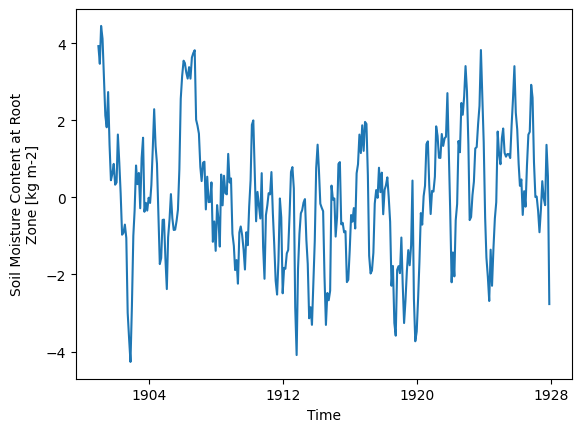

In [69]:
rm_dt_1901_1927.mean(dim=['lat', 'lon']).plot()

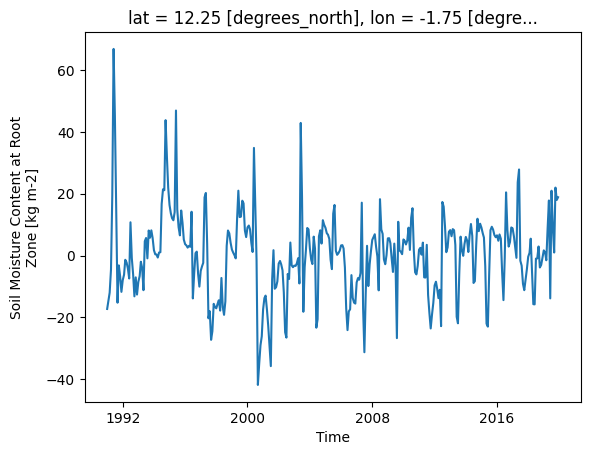

In [185]:
rm_dt_1991_2019.isel(lat=125, lon=356).plot()

In [245]:
# save rm_dt 
rm_dt_1901_1927.to_netcdf("../export/rm_dt_1901_1927.nc")
rm_dt_1991_2019.to_netcdf("../export/rm_dt_1991_2019.nc")

In [182]:
def calc_AR(da, lag=1):
    return xr.corr(
        da.isel(time=slice(None, -lag)),
        da.isel(time=slice(lag, None)),
        dim="time"
    )

In [195]:
def calc_AR(da, lag=1):
    return xr.corr(
        da,
        da.shift(time=lag),
        dim="time"
    )

In [201]:
ar1_1991_2019 = calc_AR(rm_dt_1991_2019, lag=1)
ar1_1901_1927 = calc_AR(rm_dt_1901_1927, lag=1)

In [223]:
ar1_1991_2019.mean()

<xarray.DataArray 'rootmoist' ()> Size: 8B
array(0.6847426)
Attributes:
    standard_name:  rootmoist
    units:          kg m-2
    long_name:      Soil Moisture Content at Root Zone

In [222]:
ar1_1901_1927.mean()

<xarray.DataArray 'rootmoist' ()> Size: 8B
array(0.67378709)
Attributes:
    standard_name:  rootmoist
    units:          kg m-2
    long_name:      Soil Moisture Content at Root Zone

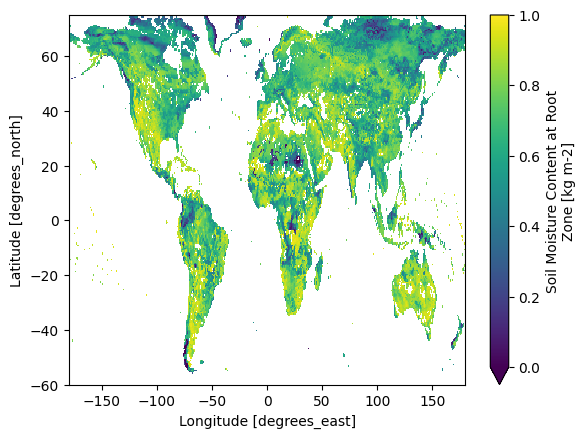

In [231]:
calc_AR(rm_dt_1991_2019, lag=1).plot(vmin=0, vmax=1, cmap='viridis')

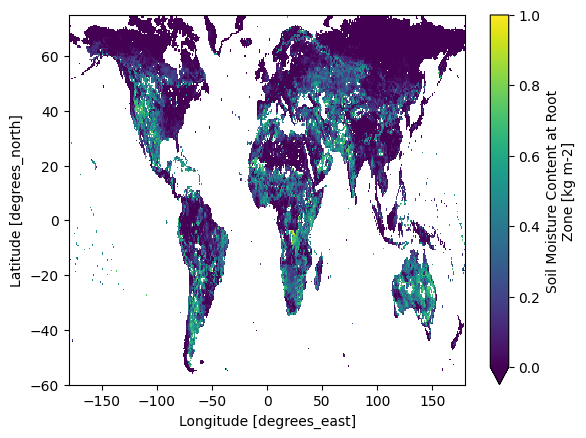

In [240]:
calc_AR(rm_dt_1991_2019, lag=6).plot(vmin=0, vmax=1, cmap='viridis')

In [207]:
memory_1901_1927 = -1/ np.log(ar1_1901_1927)
memory_1991_2019 = -1/ np.log(ar1_1991_2019)

In [241]:
memory6_1901_1927 = -1/ np.log(calc_AR(rm_dt_1901_1927, lag=6))
memory6_1991_2019 = -1/ np.log(calc_AR(rm_dt_1991_2019, lag=6))

In [208]:
memory_change = memory_1991_2019 - memory_1901_1927

(array([  565.,   866.,  1273.,  2133.,  5190., 15398., 17316.,  6901.,
         2854.,  1538.,   997.,   697.]),
 array([-6., -5., -4., -3., -2., -1.,  0.,  1.,  2.,  3.,  4.,  5.,  6.]),
 <BarContainer object of 12 artists>)

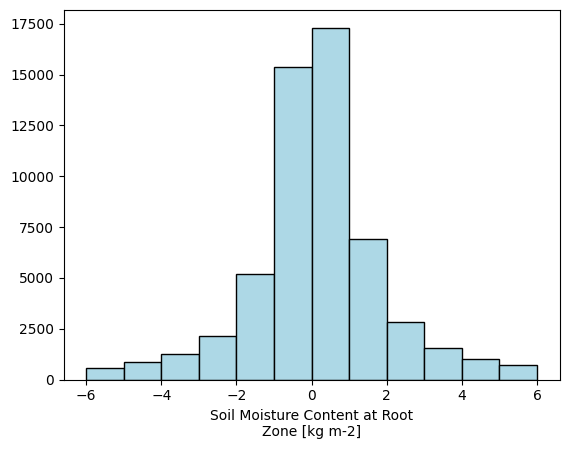

In [228]:
memory_change.plot.hist(bins=np.linspace(-6, 6, 13), color='lightblue', edgecolor='black')

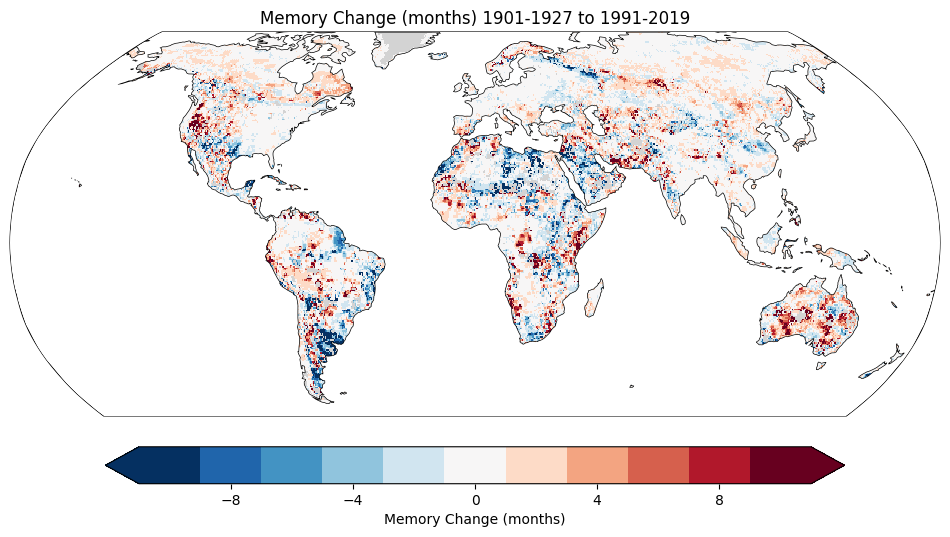

In [221]:
plot_map(memory_change, title='Memory Change (months) 1901-1927 to 1991-2019', cmap='RdBu_r', vmin=-11, vmax=11, cbar_label='Memory Change (months)', discrete_cmap=11)

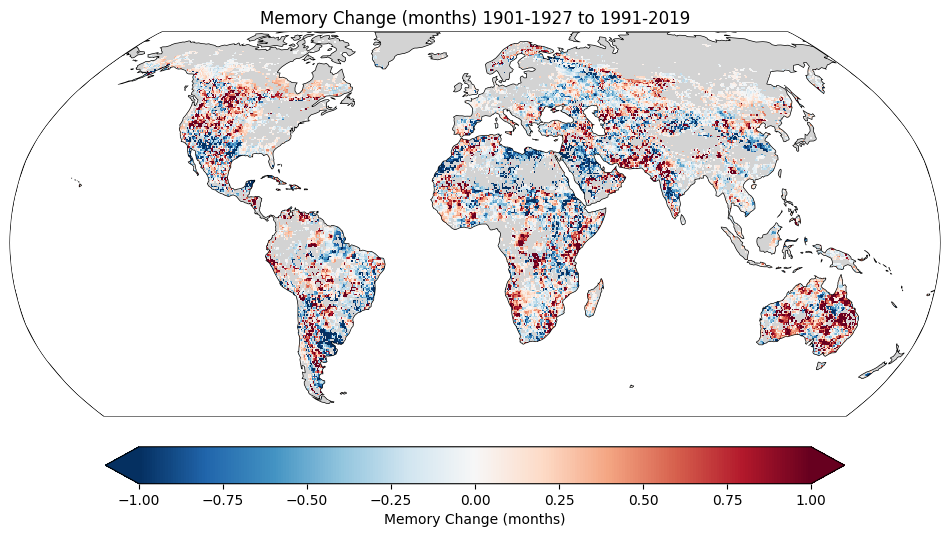

In [244]:
memoryChange6 = memory6_1991_2019 - memory6_1901_1927
plot_map(memoryChange6, title='Memory Change (months) 1901-1927 to 1991-2019', cmap='RdBu_r', vmin=-1, vmax=1, cbar_label='Memory Change (months)')

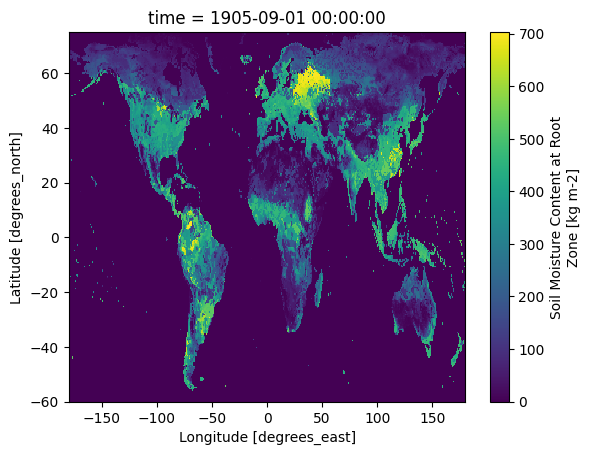

In [230]:
rm.isel(time=56).plot()

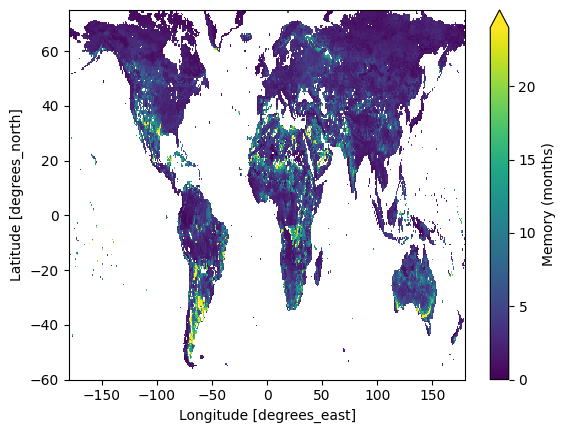

In [205]:
memory_1901_1927.plot(cmap='viridis', vmin=0, vmax=24, cbar_kwargs={'label': 'Memory (months)'})

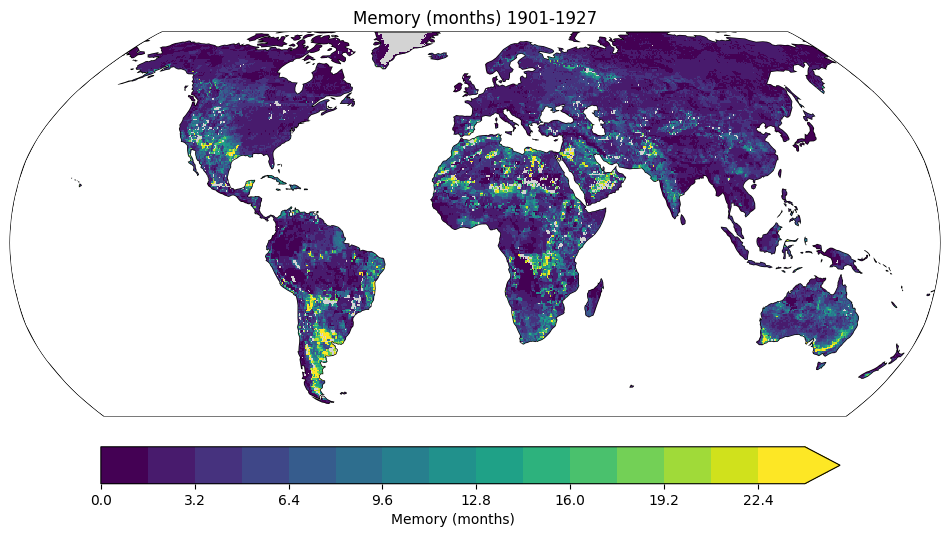

In [206]:
plot_map(memory_1901_1927, title='Memory (months) 1901-1927', cmap='viridis', vmin=0, vmax=24, cbar_label='Memory (months)', discrete_cmap=15)

(array([ 9635.,     0.,     0.,  5646.,     0.,     0.,     0.,     0.,
            0., 15043.]),
 array([-9.00719925e+15, -7.65611937e+15, -6.30503948e+15, -4.95395959e+15,
        -3.60287970e+15, -2.25179981e+15, -9.00719925e+14,  4.50359963e+14,
         1.80143985e+15,  3.15251974e+15,  4.50359963e+15]),
 <BarContainer object of 10 artists>)

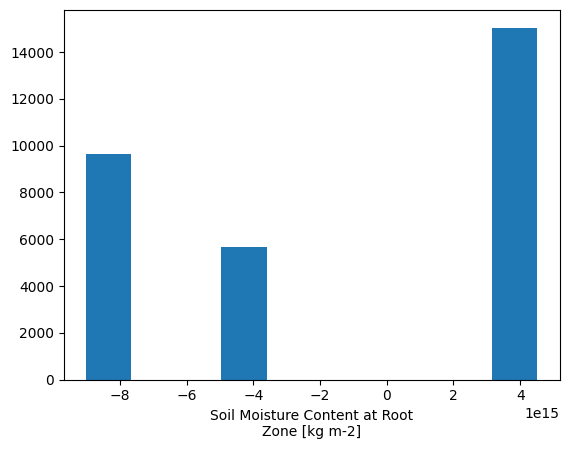

In [ ]:
memory_1901_1927.where(memory_1901_1927.values != np.inf).plot.hist()

In [ ]:
da = da.chunk({"time": -1, "lat": 45, "lon": 90})

lag1_autocorr = xr.corr(
    da.isel(time=slice(None, -1)),
    da.isel(time=slice(1, None)),
    dim="time"
)

In [ ]:
# apply AR1 calculation to each period
rm_ar1_1901_1930 = calculate_ar1(rm.sel(time=slice('1901-01-01', '1930-12-31')))
rm_ar1_1931_1960 = calculate_ar1(rm.sel(time=slice('1931-01-01', '1960-12-31')))
rm_ar1_1961_1990 = calculate_ar1(rm.sel(time=slice('1961-01-01', '1990-12-31')))
rm_ar1_1991_2020 = calculate_ar1(rm.sel(time=slice('1991-01-01', '2019-12-31')))